# PydanticAI together with Pydantic Models

In [3]:
from model import nvidia_model
from pydantic_ai import Agent

employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige. Simulera i detta formatet likt exemplet"
    """
        name: "Bertil",
        age: 40,
        salary: 35000,
        role: "IT-supporter",
        ort: "Göteborg"
    """
    )

result = await employee_simulator.run("Ge mig en data engineer som jobbar i stockholm ")
print(result.output)

        name: "Erik Andersson",
        age: 32,
        salary: 52000,
        role: "Data Engineer",
        ort: "Stockholm"


# Force a structured output using pydantic

In [4]:
from pydantic import BaseModel, Field

class EmployeeModel(BaseModel):
    name:str = Field(
        description="för och efternamn, inte jättelång, svenska eller internationella namn")
    age:int = Field(description="ålder från 18 till 67 år", ge=18, le=67)

employee1 = EmployeeModel(name="Bertil", age=40)
employee1

EmployeeModel(name='Bertil', age=40)

In [6]:
from pydantic import BaseModel, Field


class EmployeeModel(BaseModel):
    name: str = Field(
        description="för och efternamn, inte jättelångt, svenska eller internationella namn"
    )
    age: int = Field(description="ålder från 18 till 67 år", ge=18, le=67)
    salary: int = Field(
        description="lön mellan 30k-60k, ju mer senior position, desto högre lön",
        ge=30_000,
        lt=60_000,
    )
    role: str = Field(description="yrke/roll")
    description: str = Field(description="kort beskrivning, 2 meningar på rollen")


employee1 = EmployeeModel(
    name="Bertil",
    age=40,
    salary=30000,
    role="IT supporter",
    description="Hjälper folk med IT",
)

employee1

EmployeeModel(name='Bertil', age=40, salary=30000, role='IT supporter', description='Hjälper folk med IT')

In [7]:
employee_simulator = Agent(
    model=nvidia_model("nvidia/nemotron-3.5-super-vl-120b-a12b"),
    instructions="Du är expert på att simulera anställda i Sverige",
)

result = await employee_simulator.run("Ge mig en data engineer i stockholm")

result.output

'Hej! Här är en simulerad persona av en Data Engineer som arbetar i Stockholm. Denna profil är fiktiv men bygger på verkliga mönster från den svenska tech-marknaden, arbetskulturen och livsstilen i huvudstaden.\n\n---\n\n# 👤 Persona: Johan Sjöberg\n\n**Roll:** Senior Data Engineer  \n**Plats:** Stockholm (bor på Södermalm, kontor i Hammarby Sjöstad)  \n**Ålder:** 34 år  \n**Erfarenhet:** 7 år inom data och mjukvaruutveckling  \n**Bolag:** En wachstende fintech-scale-up med ca 200 anställda  \n**Språk:** Svenska och engelska (arbetsspråk är främst engelska)\n\n---\n\n## 🛠 Teknisk Stack & Verktyg\n\n*   **Språk:** Python, SQL, Scala (äldre kodbas)\n*   **Orchestration:** Apache Airflow, Dagster\n*   **Data Warehouse:** Google BigQuery (GCP)\n*   **Transformation:** dbt (data build tool)\n*   **Lagring:** GCS, PostgreSQL, Redis\n*   **CI/CD:** GitHub Actions, Docker, Kubernetes (grundläggande)\n*   **Monitoring:** Datadog, Great Expectations (datakvalitet)\n\n---\n\n## 📅 En typisk arbetsd

In [8]:
employee1.name

'Bertil'

In [9]:
result = await employee_simulator.run(
    "Ge mig en data engineer i stockholm", output_type=EmployeeModel
)
result

AgentRunResult(output=EmployeeModel(name='Erik Johansson', age=34, salary=54000, role='Data Engineer', description='Erik arbetar med att bygga och underhålla dataplattformar och ETL-pipelines i molnet. Han säkerställer att data är tillgänglig, tillförlitlig och redo för analys och rapportering.'))

In [10]:
employee2 = result.output
employee2

EmployeeModel(name='Erik Johansson', age=34, salary=54000, role='Data Engineer', description='Erik arbetar med att bygga och underhålla dataplattformar och ETL-pipelines i molnet. Han säkerställer att data är tillgänglig, tillförlitlig och redo för analys och rapportering.')

In [11]:
type(employee2)

__main__.EmployeeModel

In [12]:
employee2.name + " är cool"

'Erik Johansson är cool'

In [13]:
employee2.salary

54000

In [14]:
employee1.__dict__

{'name': 'Bertil',
 'age': 40,
 'salary': 30000,
 'role': 'IT supporter',
 'description': 'Hjälper folk med IT'}

In [15]:
employee1.__dict__.keys()

dict_keys(['name', 'age', 'salary', 'role', 'description'])

In [16]:
employee1.__dict__.values()

dict_values(['Bertil', 40, 30000, 'IT supporter', 'Hjälper folk med IT'])

In [17]:
for key, value in employee2.__dict__.items():
    print(f"{key}: {value}")

name: Erik Johansson
age: 34
salary: 54000
role: Data Engineer
description: Erik arbetar med att bygga och underhålla dataplattformar och ETL-pipelines i molnet. Han säkerställer att data är tillgänglig, tillförlitlig och redo för analys och rapportering.


### Simulate many employees

In [18]:
result = await employee_simulator.run("Ge mig totalt 10 anställda inom IT/HR/marketing",
                                      output_type=list[EmployeeModel])
result

AgentRunResult(output=[EmployeeModel(name='Emma Svensson', age=28, salary=38000, role='Systemutvecklare', description='Utvecklar webbapplikationer i Java och React för företagets kundplattform. Ansvarar för kodgranskningar och drift av testmiljöer.'), EmployeeModel(name='Johan Karlsson', age=35, salary=45000, role='IT-säkerhetsspecialist', description='Säkerställer företagets IT-säkerhet genom riskanalyser och säkerhetsuppdateringar. Håller utbildningar för personalen om säkra digitala vanor.'), EmployeeModel(name='Sofia Andersson', age=24, salary=32000, role='Supporttekniker', description='Hjälper anställda med datorproblem och installation av programvara via helpdesken. Dokumenterar vanliga ärenden i kunskapsdatabasen.'), EmployeeModel(name='Lisa Nilsson', age=31, salary=41000, role='HR-koordinator', description='Hanterar anställningsavtal, onboarding och personalregister för nya medarbetare. Stödjer cheferna i löpande HR-frågor och administration.'), EmployeeModel(name='Markus Bergm

## Task - calculate mean salary

In [19]:
employees = result.output

employees

[EmployeeModel(name='Emma Svensson', age=28, salary=38000, role='Systemutvecklare', description='Utvecklar webbapplikationer i Java och React för företagets kundplattform. Ansvarar för kodgranskningar och drift av testmiljöer.'),
 EmployeeModel(name='Johan Karlsson', age=35, salary=45000, role='IT-säkerhetsspecialist', description='Säkerställer företagets IT-säkerhet genom riskanalyser och säkerhetsuppdateringar. Håller utbildningar för personalen om säkra digitala vanor.'),
 EmployeeModel(name='Sofia Andersson', age=24, salary=32000, role='Supporttekniker', description='Hjälper anställda med datorproblem och installation av programvara via helpdesken. Dokumenterar vanliga ärenden i kunskapsdatabasen.'),
 EmployeeModel(name='Lisa Nilsson', age=31, salary=41000, role='HR-koordinator', description='Hanterar anställningsavtal, onboarding och personalregister för nya medarbetare. Stödjer cheferna i löpande HR-frågor och administration.'),
 EmployeeModel(name='Markus Bergman', age=42, salar

In [20]:
print(employees[0])

name='Emma Svensson' age=28 salary=38000 role='Systemutvecklare' description='Utvecklar webbapplikationer i Java och React för företagets kundplattform. Ansvarar för kodgranskningar och drift av testmiljöer.'


In [21]:
salary = 0

for employee in employees:
    salary += employee.salary

mean_salary = salary / len(employees)
print(mean_salary)

41300.0


## Convert to dataframe

In [22]:
employees[0].model_dump()

{'name': 'Emma Svensson',
 'age': 28,
 'salary': 38000,
 'role': 'Systemutvecklare',
 'description': 'Utvecklar webbapplikationer i Java och React för företagets kundplattform. Ansvarar för kodgranskningar och drift av testmiljöer.'}

In [30]:
import pandas as pd
df = pd.DataFrame([employee.model_dump() for employee in employees])
df.head()

,name,age,salary,role,description
0,Emma Svensson,28,38000,Systemutvecklare,Utvecklar webbapplikationer i Java och React f...
1,Johan Karlsson,35,45000,IT-säkerhetsspecialist,Säkerställer företagets IT-säkerhet genom risk...
2,Sofia Andersson,24,32000,Supporttekniker,Hjälper anställda med datorproblem och install...
3,Lisa Nilsson,31,41000,HR-koordinator,"Hanterar anställningsavtal, onboarding och per..."
4,Markus Bergman,42,52000,HR-chef,Ansvarar för den övergripande personalstrategi...


In [27]:
df.to_csv("employees.csv", index=None)

In [33]:
import matplotlib.pyplot as plt

<Axes: ylabel='name'>

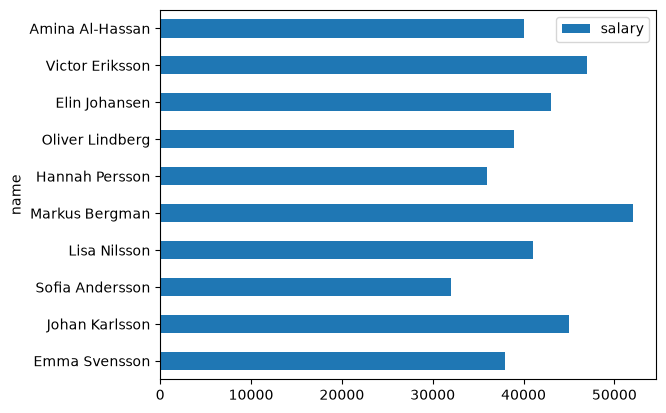

In [35]:
df.plot(kind = "barh", x = "name", y = "salary")